# 🎬 Act 1 — 누가 연체하는가?
## 우량 vs 연체 고객 행동 차이 통계 검정

**목표**: 정상(TARGET=0) vs 연체(TARGET=1) 두 그룹 간 변수별 차이를 통계적으로 검정  
**검정 방법**:
- 연속형: Mann-Whitney U test (비모수) + Cohen's d (효과 크기)
- 범주형: Chi-square test + Cramér's V

**핵심 가설**: 신분 정보 변경 시점(DAYS_LAST_PHONE_CHANGE, DAYS_ID_PUBLISH)이  
기존 통념 변수(타기관 조회 빈도)보다 더 강한 변별력을 가진다

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu, chi2_contingency
import os

# 한글 폰트
for fname in ['AppleGothic', 'Apple SD Gothic Neo']:
    try:
        fp = fm.findfont(fm.FontProperties(family=fname), fallback_to_default=False)
        if fp: plt.rcParams['font.family'] = fname; break
    except: pass
plt.rcParams['axes.unicode_minus'] = False

DATA_DIR = 'home-credit-default-risk'
print('✅ 라이브러리 로드 완료')

✅ 라이브러리 로드 완료


## 1. 데이터 로드 & 전처리

In [2]:
print('데이터 로딩 중...')
df = pd.read_csv(os.path.join(DATA_DIR, 'application_train.csv'))

# 파생 변수
df['age']                  = (-df['DAYS_BIRTH'] / 365).round(1)
df['employment_years']     = np.where(df['DAYS_EMPLOYED'] == 365243, np.nan,
                                      (-df['DAYS_EMPLOYED'] / 365).round(1))
df['credit_income_ratio']  = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
df['annuity_income_ratio'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
df['ext_source_mean']      = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)
df['ext_source_min']       = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].min(axis=1)
df['ext_source_missing']   = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].isnull().sum(axis=1)
df['phone_change_days']    = -df['DAYS_LAST_PHONE_CHANGE']
df['id_publish_days']      = -df['DAYS_ID_PUBLISH']
df['registration_days']    = -df['DAYS_REGISTRATION']

# 그룹 분리
g0 = df[df['TARGET'] == 0]  # 정상
g1 = df[df['TARGET'] == 1]  # 연체

print(f'전체: {len(df):,}명')
print(f'정상(TARGET=0): {len(g0):,}명 ({len(g0)/len(df)*100:.1f}%)')
print(f'연체(TARGET=1): {len(g1):,}명 ({len(g1)/len(df)*100:.1f}%)')

데이터 로딩 중...
전체: 307,511명
정상(TARGET=0): 282,686명 (91.9%)
연체(TARGET=1): 24,825명 (8.1%)


## 2. 연속형 변수 — Mann-Whitney U Test + Cohen's d

In [3]:
def cohens_d(x, y):
    """Cohen's d 효과 크기 계산 (절댓값)"""
    nx, ny = len(x), len(y)
    dof = nx + ny - 2
    pooled_std = np.sqrt(((nx-1)*x.std()**2 + (ny-1)*y.std()**2) / dof)
    return abs((x.mean() - y.mean()) / pooled_std) if pooled_std > 0 else 0

# 검정할 연속형 변수 목록
num_vars = [
    # 행동 변수 (Act 1 핵심)
    'phone_change_days',          # 휴대폰 변경 후 경과일
    'id_publish_days',            # 신분증 발급 후 경과일
    'registration_days',          # 등록 후 경과일
    'AMT_REQ_CREDIT_BUREAU_YEAR', # 연간 타기관 조회 수
    'AMT_REQ_CREDIT_BUREAU_MON',  # 월간 타기관 조회 수
    # 외부 신용 점수
    'ext_source_mean',
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'ext_source_min',
    # 인구통계
    'age', 'employment_years',
    'CNT_FAM_MEMBERS', 'CNT_CHILDREN',
    # 금융
    'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
    'credit_income_ratio', 'annuity_income_ratio',
    # 사회적 환경
    'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE',
    'OBS_30_CNT_SOCIAL_CIRCLE',
    # 지역
    'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY',
    'REGION_POPULATION_RELATIVE',
]

results = []
for var in num_vars:
    if var not in df.columns:
        continue
    x0 = g0[var].dropna()
    x1 = g1[var].dropna()
    if len(x0) < 30 or len(x1) < 30:
        continue
    stat, p = mannwhitneyu(x0, x1, alternative='two-sided')
    d = cohens_d(x0, x1)
    results.append({
        '변수': var,
        '정상_평균': round(x0.mean(), 4),
        '연체_평균': round(x1.mean(), 4),
        'Cohen_d': round(d, 4),
        'p_value': p,
        'p_sig': '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    })

result_df = pd.DataFrame(results).sort_values('Cohen_d', ascending=False)
result_df['rank'] = range(1, len(result_df)+1)
print('=== 연속형 변수 검정 결과 (Cohen\'s d 내림차순) ===')
print(result_df[['rank','변수','정상_평균','연체_평균','Cohen_d','p_sig']].to_string(index=False))

=== 연속형 변수 검정 결과 (Cohen's d 내림차순) ===
 rank                          변수       정상_평균       연체_평균  Cohen_d p_sig
    1             ext_source_mean      0.5191      0.3970   0.8360   ***
    2              ext_source_min      0.4099      0.2824   0.6921   ***
    3                EXT_SOURCE_3      0.5210      0.3907   0.6795   ***
    4                EXT_SOURCE_1      0.5115      0.3870   0.5971   ***
    5                EXT_SOURCE_2      0.5235      0.4109   0.5968   ***
    6                         age     44.2142     40.7805   0.2881   ***
    7            employment_years      6.6798      4.9722   0.2673   ***
    8 REGION_RATING_CLIENT_W_CITY      2.0224      2.1348   0.2239   ***
    9        REGION_RATING_CLIENT      2.0436      2.1536   0.2166   ***
   10           phone_change_days    976.3883    808.7968   0.2030   ***
   11             id_publish_days   3017.2198   2732.0996   0.1891   ***
   12           registration_days   5029.9411   4487.1270   0.1542   ***
   13  REGION

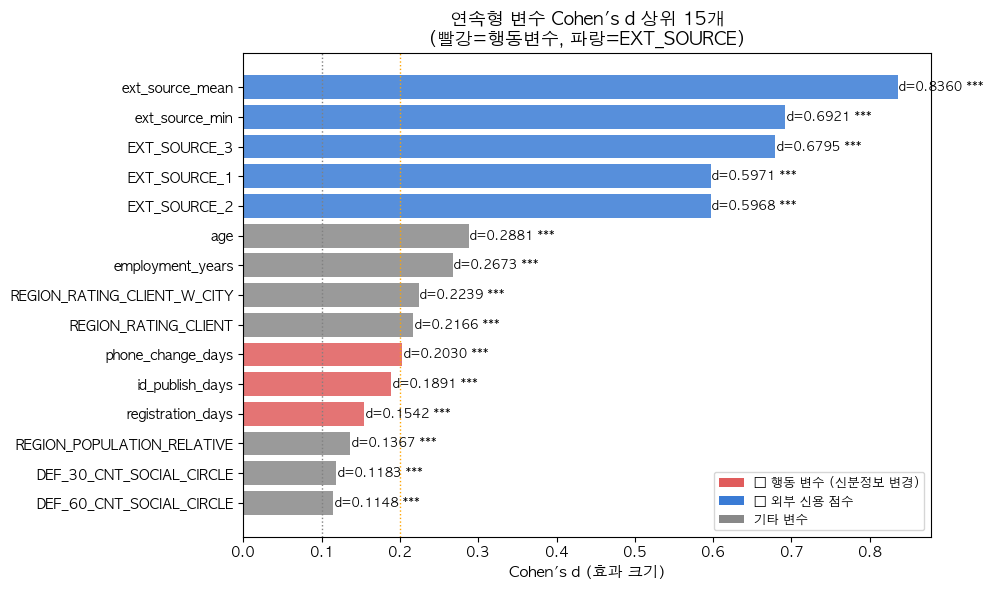


✅ 그래프 생성 완료


In [4]:
# ── 상위 15개 시각화 ──────────────────────────────────────
top15 = result_df.head(15)
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#e05c5c' if v in ['phone_change_days','id_publish_days','registration_days']
          else '#3a7bd5' if 'ext_source' in v.lower() or 'EXT' in v
          else '#888888'
          for v in top15['변수']]

bars = ax.barh(top15['변수'][::-1], top15['Cohen_d'][::-1], color=colors[::-1], alpha=0.85)
for bar, (_, row) in zip(bars, top15[::-1].iterrows()):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f"d={row['Cohen_d']:.4f} {row['p_sig']}",
            va='center', fontsize=9)

ax.axvline(0.1, color='gray', lw=1, ls=':', label='작은 효과(0.1)')
ax.axvline(0.2, color='orange', lw=1, ls=':', label='중간 효과(0.2)')
ax.set_xlabel("Cohen's d (효과 크기)", fontsize=11)
ax.set_title('연속형 변수 Cohen\'s d 상위 15개\n(빨강=행동변수, 파랑=EXT_SOURCE)', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e05c5c', label='🔥 행동 변수 (신분정보 변경)'),
    Patch(facecolor='#3a7bd5', label='⭐ 외부 신용 점수'),
    Patch(facecolor='#888888', label='기타 변수')
]
ax.legend(handles=legend_elements, fontsize=9)
plt.tight_layout()
plt.show()
print('\n✅ 그래프 생성 완료')

## 3. 범주형 변수 — Chi-square Test + Cramér's V

In [5]:
def cramers_v(x, y):
    """Cramér's V 연관성 계수 (0=무관, 1=완전연관)"""
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    phi2 = chi2 / n
    r, k = ct.shape
    v = np.sqrt(phi2 / min(k-1, r-1)) if min(k-1, r-1) > 0 else 0
    return v, p

cat_vars = [
    'CODE_GENDER', 'NAME_CONTRACT_TYPE',
    'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
    'OCCUPATION_TYPE', 'ORGANIZATION_TYPE',
    'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
    'WEEKDAY_APPR_PROCESS_START',
    'REGION_RATING_CLIENT',
]

cat_results = []
for var in cat_vars:
    if var not in df.columns:
        continue
    tmp = df[[var, 'TARGET']].dropna()
    if len(tmp) < 100:
        continue
    v, p = cramers_v(tmp[var], tmp['TARGET'])
    # 연체율 최고/최저 카테고리 찾기
    dr = tmp.groupby(var)['TARGET'].mean() * 100
    cat_results.append({
        '변수': var,
        'Cramers_V': round(v, 4),
        'p_value': p,
        'p_sig': '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns',
        '최고위험_카테고리': f"{dr.idxmax()}({dr.max():.1f}%)",
        '최저위험_카테고리': f"{dr.idxmin()}({dr.min():.1f}%)"
    })

cat_df = pd.DataFrame(cat_results).sort_values('Cramers_V', ascending=False)
print('=== 범주형 변수 검정 결과 (Cramér\'s V 내림차순) ===')
print(cat_df.to_string(index=False))

=== 범주형 변수 검정 결과 (Cramér's V 내림차순) ===
                        변수  Cramers_V       p_value p_sig                 최고위험_카테고리              최저위험_카테고리
           OCCUPATION_TYPE     0.0815 3.784500e-288   *** Low-skill Laborers(17.2%)      Accountants(4.8%)
         ORGANIZATION_TYPE     0.0723 5.224541e-299   ***  Transport: type 3(15.8%)    Trade: type 4(3.1%)
          NAME_INCOME_TYPE     0.0638 1.928146e-266   ***    Maternity leave(40.0%)      Businessman(0.0%)
      REGION_RATING_CLIENT     0.0589 1.828316e-232   ***                  3(11.1%)                1(4.8%)
       NAME_EDUCATION_TYPE     0.0576 2.447681e-219   ***    Lower secondary(10.9%)  Academic degree(1.8%)
               CODE_GENDER     0.0547 1.129022e-200   ***                  M(10.1%)              XNA(0.0%)
        NAME_FAMILY_STATUS     0.0405 7.744842e-107   ***      Civil marriage(9.9%)          Unknown(0.0%)
         NAME_HOUSING_TYPE     0.0370  1.099089e-88   ***   Rented apartment(12.3%) Office apartment(6.6%

## 4. ⭐ 행동 변수 심화 분석 — Act 1 핵심

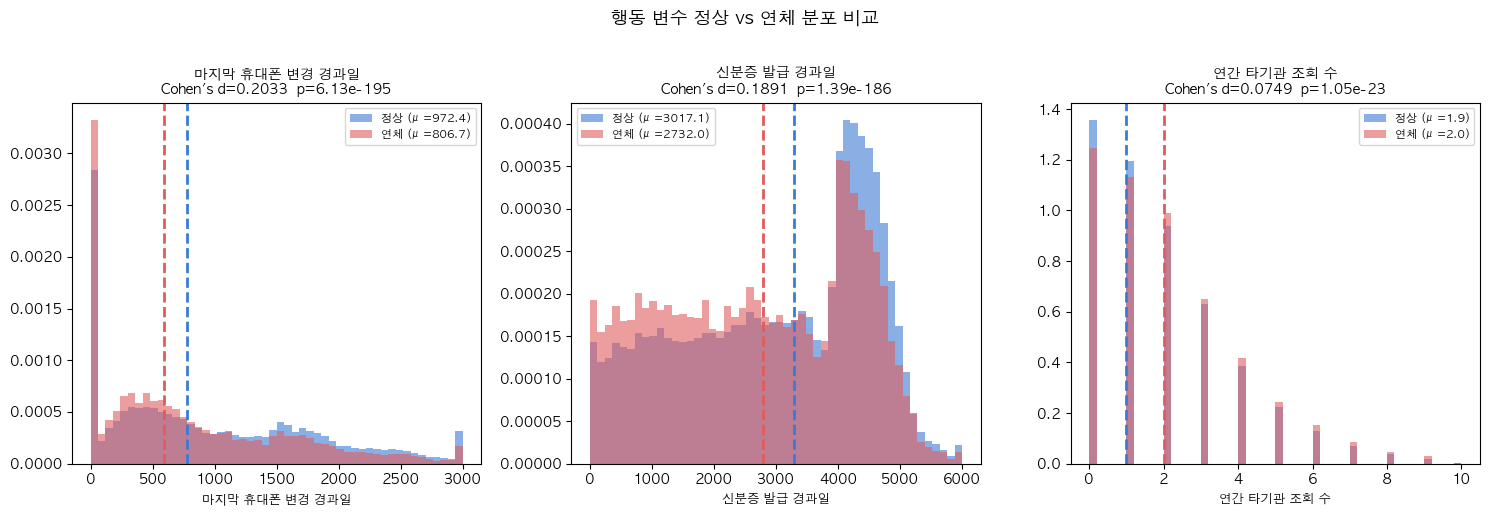

In [6]:
# 행동 변수 3개 분포 비교
behavior_vars = [
    ('phone_change_days',          '마지막 휴대폰 변경 경과일', 3000),
    ('id_publish_days',            '신분증 발급 경과일',        6000),
    ('AMT_REQ_CREDIT_BUREAU_YEAR', '연간 타기관 조회 수',       10),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (var, label, clip_val) in zip(axes, behavior_vars):
    d0 = g0[var].dropna().clip(0, clip_val)
    d1 = g1[var].dropna().clip(0, clip_val)
    _, p = mannwhitneyu(d0, d1, alternative='two-sided')
    d = cohens_d(d0, d1)
    ax.hist(d0, bins=50, color='#3a7bd5', alpha=0.6,
            label=f'정상 (μ={d0.mean():.1f})', density=True)
    ax.hist(d1, bins=50, color='#e05c5c', alpha=0.6,
            label=f'연체 (μ={d1.mean():.1f})', density=True)
    ax.axvline(d0.median(), color='#3a7bd5', lw=2, ls='--')
    ax.axvline(d1.median(), color='#e05c5c', lw=2, ls='--')
    ax.set_title(f'{label}\nCohen\'s d={d:.4f}  p={p:.2e}', fontsize=10, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_xlabel(label, fontsize=9)

plt.suptitle('행동 변수 정상 vs 연체 분포 비교', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
# 시그널 강도 비교 요약표
print('=' * 65)
print('📊 Act 1 핵심 결과 — 시그널 강도 순위')
print('=' * 65)
print(f"{'순위':<5} {'변수':<35} {'Cohen\'s d':<12} {'유의성':<8}")
print('-' * 65)
for i, (_, row) in enumerate(result_df.head(10).iterrows(), 1):
    star = '🔥' if row['변수'] in ['phone_change_days','id_publish_days'] else \
           '⭐' if 'ext' in row['변수'].lower() or 'EXT' in row['변수'] else '  '
    print(f"{i:<5} {star} {row['변수']:<33} {row['Cohen_d']:<12} {row['p_sig']}")
print('=' * 65)

# 휴대폰 변경 vs 타기관 조회 배율
d_phone  = result_df[result_df['변수']=='phone_change_days']['Cohen_d'].values
d_credit = result_df[result_df['변수']=='AMT_REQ_CREDIT_BUREAU_YEAR']['Cohen_d'].values
if len(d_phone) > 0 and len(d_credit) > 0:
    ratio = d_phone[0] / d_credit[0]
    print(f'\n🔥 휴대폰 변경 시그널 강도: 타기관 조회의 {ratio:.1f}배')
print('\n✅ Act 1 분석 완료')

📊 Act 1 핵심 결과 — 시그널 강도 순위
순위    변수                                  Cohen's d    유의성     
-----------------------------------------------------------------
1     ⭐ ext_source_mean                   0.836        ***
2     ⭐ ext_source_min                    0.6921       ***
3     ⭐ EXT_SOURCE_3                      0.6795       ***
4     ⭐ EXT_SOURCE_1                      0.5971       ***
5     ⭐ EXT_SOURCE_2                      0.5968       ***
6        age                               0.2881       ***
7        employment_years                  0.2673       ***
8        REGION_RATING_CLIENT_W_CITY       0.2239       ***
9        REGION_RATING_CLIENT              0.2166       ***
10    🔥 phone_change_days                 0.203        ***

🔥 휴대폰 변경 시그널 강도: 타기관 조회의 2.7배

✅ Act 1 분석 완료


## 5. 결과 저장

In [8]:
OUT_DIR = '.'
result_df.to_csv(os.path.join(OUT_DIR, 'act1_continuous_test_results.csv'), index=False, encoding='utf-8-sig')
cat_df.to_csv(os.path.join(OUT_DIR, 'act1_categorical_test_results.csv'), index=False, encoding='utf-8-sig')
print('✅ 결과 저장 완료')
print(f'  → act1_continuous_test_results.csv')
print(f'  → act1_categorical_test_results.csv')

✅ 결과 저장 완료
  → act1_continuous_test_results.csv
  → act1_categorical_test_results.csv
